In [65]:
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

life_table = pd.read_csv('lifeTable.csv')
cash_rates = pd.read_csv('cash_rate.csv')
rba = cash_rates[['Year', 'RBA']]

In [66]:

tickers = {
    'Aus_Shares':   'VAS.AX',  
    'Intl_Shares':  'VGS.AX',  
    'Property':     'VAP.AX',   
    'Infrastructure': 'IFRA.AX',
    'Aus_Bonds':    'VAF.AX',  
    'Intl_Bonds':   'VIF.AX', 
    'Cash':         'AAA.AX'
}


prices = yf.download(list(tickers.values()), start='2000-01-01', interval='1mo',
                     auto_adjust=True, progress=False)['Close']
prices = prices.rename(columns={v: k for k, v in tickers.items()})
prices = prices[list(tickers.keys())]


monthly_returns = prices.pct_change().dropna()

annual_mean = monthly_returns.mean() * 12
annual_cov = monthly_returns.cov() * 12
annual_var = np.diag(annual_cov)
annual_vol = np.sqrt(annual_var)
correlation = monthly_returns.corr()

In [67]:
number_of_simulations = 1000
px_dict = {}
dt = 1

#Survival Rate Calculations (px)
for person in life_table.columns[1:]:
  px_dict[person] = []
  for n in range(0, len(life_table) - 1):
    if life_table[person][n] == 0:
      px = 0
    else:
      px = life_table[person][n+1] / life_table[person][n]
    px_dict[person].append(px)
survival_rate = pd.DataFrame(px_dict)

rba_cash_rate = rba['RBA'][120:]
delta_r = rba_cash_rate.diff().dropna()
covariance = np.cov(delta_r, rba_cash_rate[1:])
b = covariance[0,1] / np.var(rba_cash_rate[1:])
a = np.mean(delta_r) - b * np.mean(rba_cash_rate[1:])
kappa = -b
theta = a / kappa

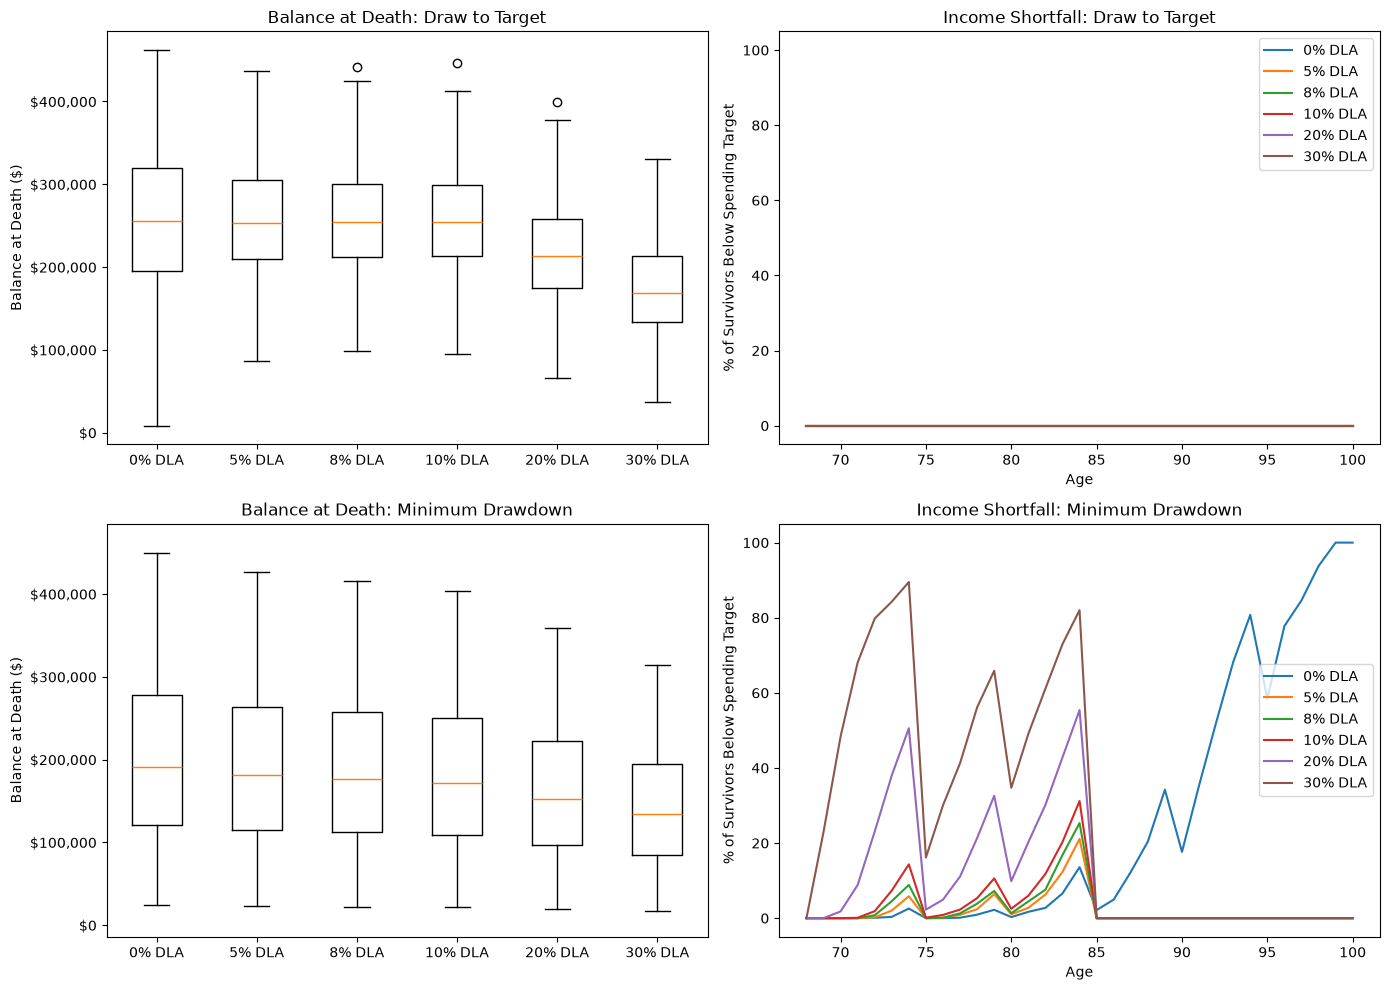


DRAW TO TARGET
  0% | premium $        0 | DLA income $       0 | mean bequest $  255,195 | ABP exhausted   1.1% (avg age 98.4) | mean cum. shortfall $       0 | person-years short 0
  5% | premium $   20,000 | DLA income $   8,961 | mean bequest $  257,241 | ABP exhausted   0.0% (avg age n/a) | mean cum. shortfall $       0 | person-years short 0
  8% | premium $   30,000 | DLA income $  13,442 | mean bequest $  257,792 | ABP exhausted   0.0% (avg age n/a) | mean cum. shortfall $       0 | person-years short 0
 10% | premium $   40,000 | DLA income $  17,922 | mean bequest $  256,929 | ABP exhausted   0.0% (avg age n/a) | mean cum. shortfall $       0 | person-years short 0
 20% | premium $   80,000 | DLA income $  35,844 | mean bequest $  216,785 | ABP exhausted   0.0% (avg age n/a) | mean cum. shortfall $       0 | person-years short 0
 30% | premium $  120,000 | DLA income $  53,767 | mean bequest $  173,370 | ABP exhausted   0.0% (avg age n/a) | mean cum. shortfall $       0 | pe

In [68]:
random.seed(1)
weights = {
    "Conservative": [0.1, 0.12, 0.04, 0.04, 0.25, 0.2, 0.25],
    "Balanced": [0.18, 0.2, 0.06, 0.06, 0.2, 0.15, 0.15],
    "Growth": [0.25, 0.3, 0.075, 0.075, 0.12, 0.1, 0.08]
}


survival_rate.iloc[100:] = 0
min_drawdown_rates = {
    65: 0.05,
    74: 0.05,
    79: 0.06,
    84: 0.07,
    89: 0.09,
    94: 0.11,
    100: 0.14
}
key_list = list(min_drawdown_rates.keys())

max_pension = 1237.70 * 26
assets_threshold = 333_000
assets_taper = 78
income_free_area = 226 * 26
income_taper = 0.5
deeming_threshold = 66_800
deeming_lower = 0.0175
deeming_upper = 0.0375
inflation = 0.025

def age_pension(balance, age, dla_price = 0, dla_income = 0,
                dla_asset_pct = 0.6, dla_asset_pct_later = 0.3, dla_switch_age = 84,
                dla_income_pct = 0.6):
    if age <= dla_switch_age:
        dla_assets = dla_price * dla_asset_pct
    else:
        dla_assets = dla_price * dla_asset_pct_later
    total_assets = balance + dla_assets
    assets_pension = max_pension - assets_taper * max(0, total_assets - assets_threshold) / 1000

    deemed_income = (min(balance, deeming_threshold) * deeming_lower
                     + max(0, balance - deeming_threshold) * deeming_upper)
    total_income = deemed_income + dla_income * dla_income_pct
    income_pension = max_pension - income_taper * max(0, total_income - income_free_area)

    return max(0, min(assets_pension, income_pension, max_pension))

def dla_income_for_target(target, price_per_dollar, age = 85):
    low, high = 0, target
    for _ in range(50):
        x = (low + high) / 2
        total = x + age_pension(0, age, dla_price = price_per_dollar * x, dla_income = x)
        if total < target:
            low = x
        else:
            high = x
    return high

def dla_price_per_dollar(age1 = 67, deferral_age = 85, max_age = 100, loading = 0.1):
    px = survival_rate['Australia_Male']
    cash_rate = [rba['RBA'][120]]
    for t in range(max_age - age1):
        cash_rate.append(cash_rate[-1] + kappa * (theta - cash_rate[-1]))
    v = np.cumprod([1] + [1 / (1 + r / 100 - inflation) for r in cash_rate[:-1]])
    pv = 0
    tpx = 1
    for t in range(0, max_age - age1 + 1):
        if age1 + t >= deferral_age:
            pv += tpx * v[t]
        tpx *= px[age1 + t]
    return pv * (1 + loading)

price_per_dollar = dla_price_per_dollar()
dla_price_basis = price_per_dollar
allocations = [0, 0.05, 0.075, 0.1, 0.2, 0.3]
def policy_asset_pct(allocation):
    exempt = 0.4 + 12 * max(0, min(allocation, 0.10) - 0.05)
    return 1 - min(exempt, 1)
def capped_asset_pct(allocation):
    # graduated exemption applies only to the first 10% of the balance; any excess is 60% assessable
    if allocation <= 0:
        return 0.6
    covered = min(allocation, 0.10) / allocation
    return covered * policy_asset_pct(min(allocation, 0.10)) + (1 - covered) * 0.6

ASSET_RULES = {
    "current": lambda a: 0.6,
    "graduated": policy_asset_pct,
    "graduated_capped": capped_asset_pct,
    "flat_full": lambda a: 0.0,
}
spending_target = 44_000
liquid_return = 1.043 / 1.025 - 1

def monte_carlo_simulation(allocation, age1 = 67, abp_balance = 400_000,
                           return_type = "Conservative", price = dla_price_basis,
                           target = spending_target, drawdown_rule = "target",
                           policy = False, asset_rule = None, income_pct = 0.6,
                           co_contribution = 0.0):
    random.seed(1)
    np.random.seed(1)
    member_paid = allocation * abp_balance
    premium_val = member_paid / (1 - co_contribution)
    govt_contribution = premium_val - member_paid
    dla_income_val = premium_val / price
    if asset_rule is None:
        asset_rule = "graduated" if policy else "current"
    asset_pct = ASSET_RULES[asset_rule](allocation)

    bequests, cumulative_shortfalls, exhaustion_ages = [], [], []
    ruin_ages, pensions, shorts_pre85, shorts_post85 = [], [], [], []
    shortfall_number = {x: 0 for x in range(67, 101)}
    alive_count = {x: 0 for x in range(67, 101)}
    ruined_count = {x: 0 for x in range(67, 101)}
    w = np.array(weights[return_type])

    for _ in range(number_of_simulations):
        option_returns = np.random.multivariate_normal(annual_mean, annual_cov, size = 33) @ w
        current_age = age1
        balance = abp_balance - member_paid
        liquid = 0
        total_shortfall = short_pre85 = short_post85 = 0
        lifetime_pension = 0
        exhausted_age = None
        ruin_age = None
        px_male = survival_rate['Australia_Male'][current_age]

        while random.random() < px_male:
            current_age += 1
            for n in range(1, len(key_list)):
                if key_list[n-1] < current_age <= key_list[n]:
                    drawdown = min_drawdown_rates[key_list[n]]
                    break

            dla_payment = dla_income_val if current_age >= 85 else 0
            pension = age_pension(balance + liquid, current_age, dla_price = premium_val,
                                  dla_income = dla_payment, dla_asset_pct = asset_pct,
                                  dla_income_pct = income_pct)
            lifetime_pension += pension

            if drawdown_rule == "minimum":
                abp_draw = balance * drawdown
                spending = pension + dla_payment + abp_draw
            else:
                need = max(0, target - pension - dla_payment)
                abp_draw = min(balance, max(balance * drawdown, need))
                from_liquid = min(liquid, max(0, need - abp_draw))
                excess = max(0, abp_draw - need)
                liquid += excess - from_liquid
                spending = pension + dla_payment + abp_draw - excess + from_liquid

            shortfall = max(0, target - spending)
            total_shortfall += shortfall
            if current_age < 85:
                short_pre85 += shortfall
            else:
                short_post85 += shortfall

            r = option_returns[current_age - age1 - 1] - inflation
            balance = (balance - abp_draw) * (1 + r)
            liquid = liquid * (1 + liquid_return)
            if balance <= 1:
                balance = 0
                if exhausted_age is None:
                    exhausted_age = current_age

            px_male = survival_rate['Australia_Male'][current_age]
            alive_count[current_age] += 1
            if ruin_age is None and balance + liquid <= 1:
                ruin_age = current_age
            if ruin_age is not None:
                ruined_count[current_age] += 1
            if shortfall > 1:
                shortfall_number[current_age] += 1

        bequests.append(balance + liquid)
        cumulative_shortfalls.append(total_shortfall)
        exhaustion_ages.append(exhausted_age)
        ruin_ages.append(ruin_age)
        pensions.append(lifetime_pension)
        shorts_pre85.append(short_pre85)
        shorts_post85.append(short_post85)

    plot_ages = [a for a in alive_count if alive_count[a] > 0]
    exhausted = [a for a in exhaustion_ages if a is not None]
    return {
        "premium": premium_val,
        "dla_income": dla_income_val,
        "bequests": bequests,
        "mean_bequest": np.mean(bequests),
        "ages": plot_ages,
        "shortfall_pct": [shortfall_number[a] / alive_count[a] * 100 for a in plot_ages],
        "person_years_short": sum(shortfall_number.values()),
        "mean_cum_shortfall": np.mean(cumulative_shortfalls),
        "mean_short_pre85": np.mean(shorts_pre85),
        "mean_short_post85": np.mean(shorts_post85),
        "pct_no_shortfall": np.mean([s < 1 for s in cumulative_shortfalls]) * 100,
        "pct_exhausted": len(exhausted) / number_of_simulations * 100,
        "mean_exhaustion_age": np.mean(exhausted) if exhausted else None,
        "ruin_pct_by_age": [ruined_count[a] / alive_count[a] * 100 for a in plot_ages],
        "lifetime_ruin_pct": np.mean([r is not None for r in ruin_ages]) * 100,
        "mean_lifetime_pension": np.mean(pensions),
        "govt_cost": np.mean(pensions) + govt_contribution,
    }

results = {a: monte_carlo_simulation(a) for a in allocations}
results_min = {a: monte_carlo_simulation(a, drawdown_rule = "minimum") for a in allocations}
labels = [f'{a:.0%} DLA' for a in allocations]
dollar_format = plt.FuncFormatter(lambda x, _: f'${x:,.0f}')

fig, axs = plt.subplots(2, 2, figsize = (14, 10), sharey = 'col')

for row, (rule_name, res_set) in enumerate([("Draw to Target", results), ("Minimum Drawdown", results_min)]):
    axs[row, 0].boxplot([res['bequests'] for res in res_set.values()])
    axs[row, 0].set_xticks(range(1, len(allocations) + 1), labels)
    axs[row, 0].set_title(f'Balance at Death: {rule_name}')
    axs[row, 0].set_ylabel('Balance at Death ($)')
    axs[row, 0].yaxis.set_major_formatter(dollar_format)

    for label, res in zip(labels, res_set.values()):
        axs[row, 1].plot(res['ages'], res['shortfall_pct'], label = label)
    axs[row, 1].set_title(f'Income Shortfall: {rule_name}')
    axs[row, 1].set_xlabel('Age')
    axs[row, 1].set_ylabel('% of Survivors Below Spending Target')
    axs[row, 1].legend()

plt.tight_layout()
plt.show()

for rule_name, res_set in [("DRAW TO TARGET", results), ("MINIMUM DRAWDOWN", results_min)]:
    print(f"\n{rule_name}")
    for a, res in res_set.items():
        exh_age = f"{res['mean_exhaustion_age']:.1f}" if res['mean_exhaustion_age'] else "n/a"
        print(f"{a:>4.0%} | premium ${res['premium']:>9,.0f} | DLA income ${res['dla_income']:>8,.0f} | "
              f"mean bequest ${np.mean(res['bequests']):>9,.0f} | "
              f"ABP exhausted {res['pct_exhausted']:>5.1f}% (avg age {exh_age}) | "
              f"mean cum. shortfall ${res['mean_cum_shortfall']:>8,.0f} | person-years short {res['person_years_short']}")


  0% DLA | max sustainable spending: $ 47,383 | no-shortfall rate 95.3% | mean bequest $  199,061
  5% DLA | max sustainable spending: $ 49,727 | no-shortfall rate 95.7% | mean bequest $  162,002
  8% DLA | max sustainable spending: $ 50,703 | no-shortfall rate 95.1% | mean bequest $  144,798
 10% DLA | max sustainable spending: $ 51,289 | no-shortfall rate 95.8% | mean bequest $  133,697
 20% DLA | max sustainable spending: $ 50,508 | no-shortfall rate 95.6% | mean bequest $  115,870
 30% DLA | max sustainable spending: $ 48,359 | no-shortfall rate 95.7% | mean bequest $  103,694


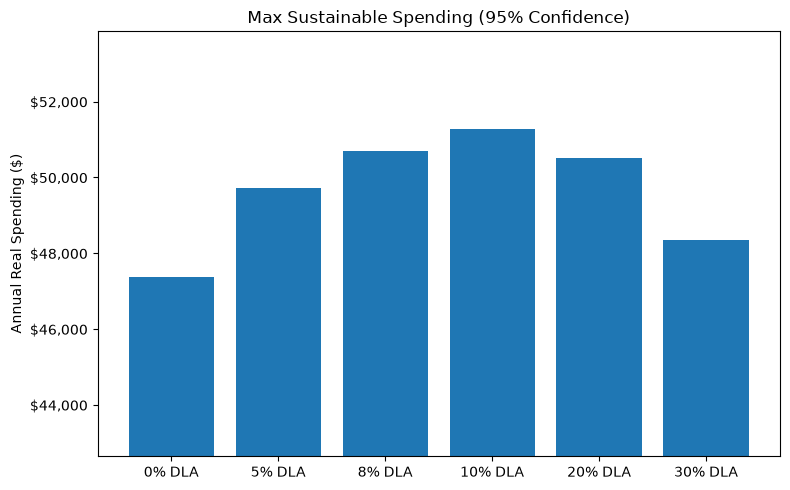

In [69]:
confidence = 95

def max_sustainable_spending(allocation, low = 30_000, high = 80_000, tol = 250, **kwargs):
    while high - low > tol:
        mid = (low + high) / 2
        res = monte_carlo_simulation(allocation, target = mid, **kwargs)
        if res['pct_no_shortfall'] >= confidence:
            low = mid
        else:
            high = mid
    return low

sustainable = {}
for a in allocations:
    s = max_sustainable_spending(a)
    res = monte_carlo_simulation(a, target = s)
    sustainable[a] = s
    print(f"{a:>4.0%} DLA | max sustainable spending: ${s:>7,.0f} | "
          f"no-shortfall rate {res['pct_no_shortfall']:.1f}% | mean bequest ${np.mean(res['bequests']):>9,.0f}")

fig, ax = plt.subplots(figsize = (8, 5))
ax.bar(labels, list(sustainable.values()))
ax.set_title(f'Max Sustainable Spending ({confidence}% Confidence)')
ax.set_ylabel('Annual Real Spending ($)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_ylim(min(sustainable.values()) * 0.9, max(sustainable.values()) * 1.05)
plt.tight_layout()
plt.show()

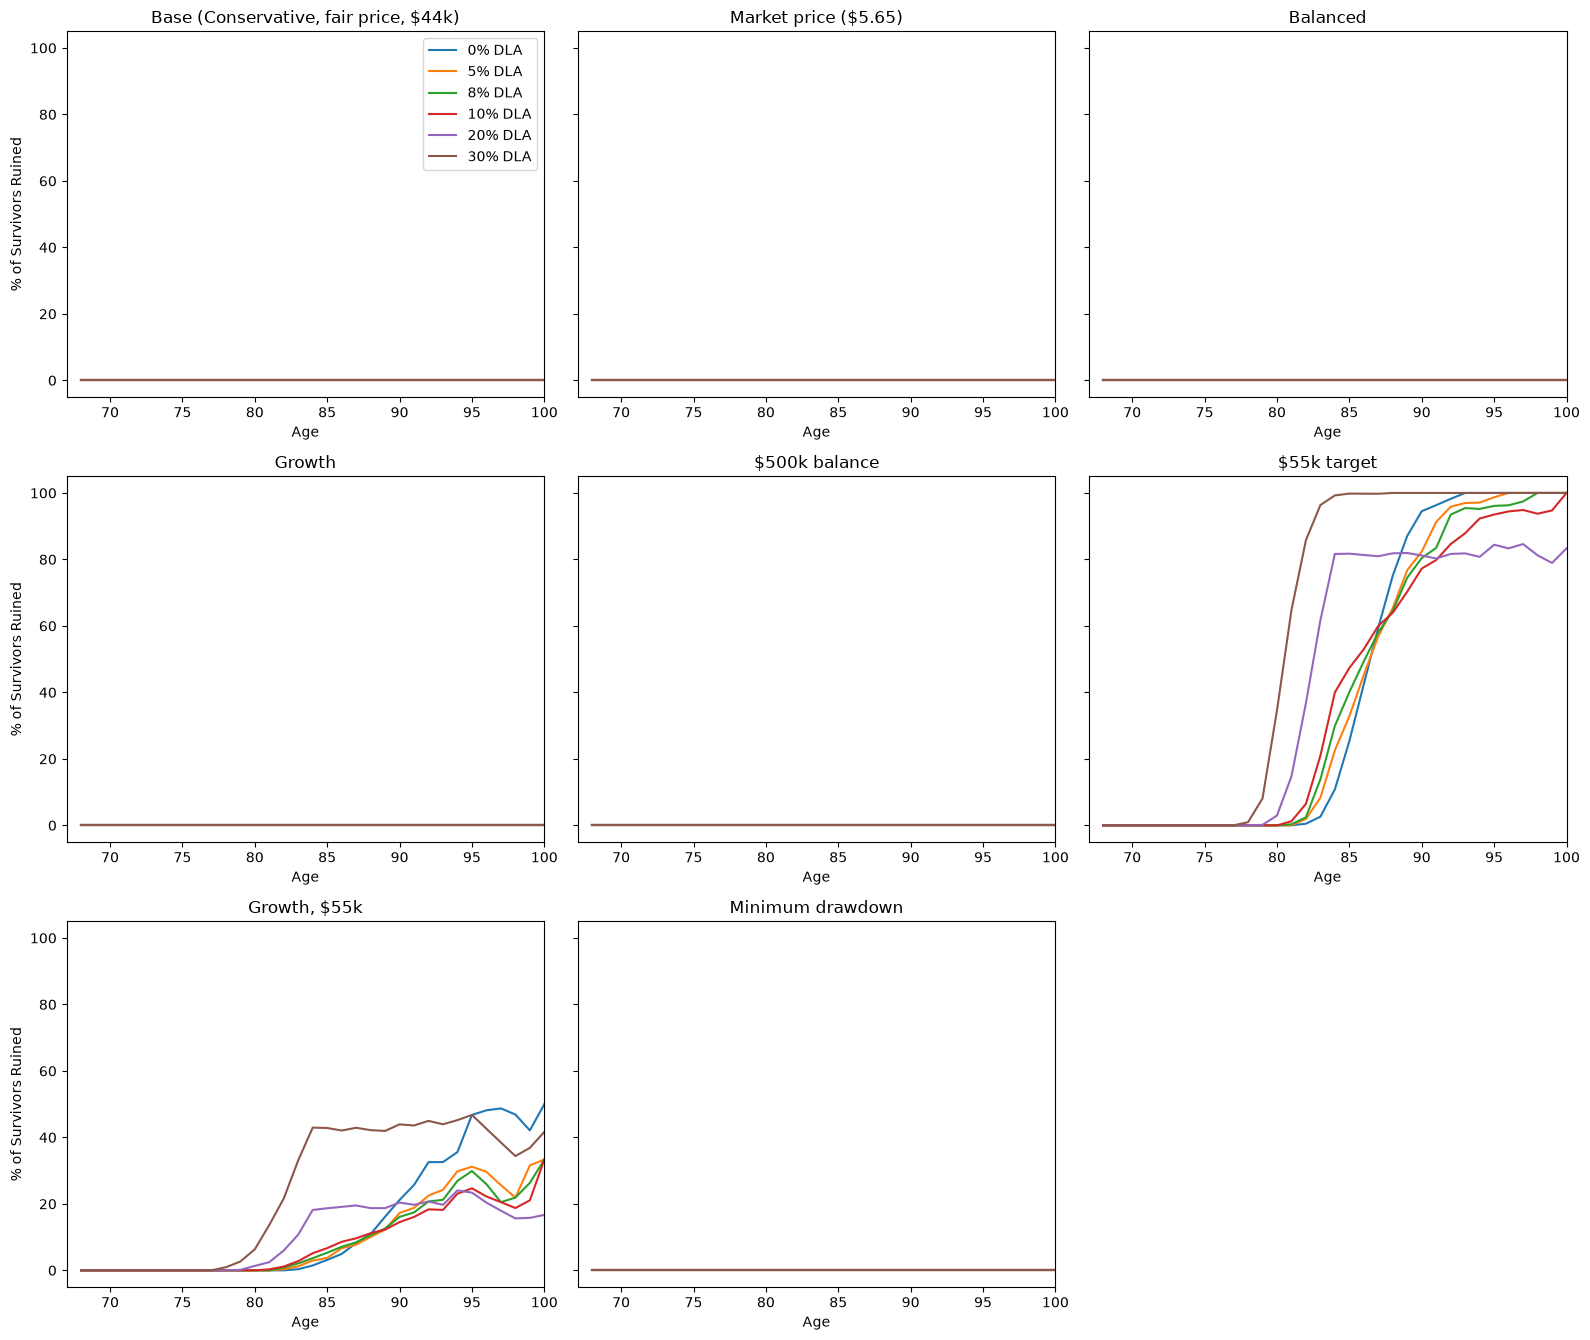

Lifetime probability of ruin (%)
                                       0% DLA  5% DLA  8% DLA  10% DLA  \
Base (Conservative, fair price, $44k)     0.0     0.0     0.0      0.0   
Market price ($5.65)                      0.0     0.0     0.0      0.0   
Balanced                                  0.0     0.0     0.0      0.0   
Growth                                    0.0     0.0     0.0      0.0   
$500k balance                             0.0     0.0     0.0      0.0   
$55k target                              40.0    38.9    39.1     39.7   
Growth, $55k                             11.2     8.1     7.8      7.2   
Minimum drawdown                          0.0     0.0     0.0      0.0   

                                       20% DLA  30% DLA  
Base (Conservative, fair price, $44k)      0.0      0.0  
Market price ($5.65)                       0.0      0.0  
Balanced                                   0.0      0.0  
Growth                                     0.0      0.0  
$500k bala

In [70]:
scenarios = {
    "Base (Conservative, fair price, $44k)": {},
    "Market price ($5.65)": {"price": 5.65},
    "Balanced": {"return_type": "Balanced"},
    "Growth": {"return_type": "Growth"},
    "$500k balance": {"abp_balance": 500_000},
    "$55k target": {"target": 55_000},
    "Growth, $55k": {"return_type": "Growth", "target": 55_000},
    "Minimum drawdown": {"drawdown_rule": "minimum"},
}

ruin_table = pd.DataFrame(index = list(scenarios.keys()), columns = labels, dtype = float)
n_cols = 3
n_rows = int(np.ceil(len(scenarios) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize = (16, 4.5 * n_rows), sharey = True)

for ax, (name, kwargs) in zip(axs.flat, scenarios.items()):
    for a, label in zip(allocations, labels):
        res = monte_carlo_simulation(a, **kwargs)
        ruin_table.loc[name, label] = res['lifetime_ruin_pct']
        ax.plot(res['ages'], res['ruin_pct_by_age'], label = label)
    ax.set_title(name)
    ax.set_xlabel('Age')
    ax.set_xlim(67, 100)

for ax in axs[:, 0]:
    ax.set_ylabel('% of Survivors Ruined')
for ax in axs.flat[len(scenarios):]:
    ax.set_visible(False)
axs[0, 0].legend()
plt.tight_layout()
plt.show()

print("Lifetime probability of ruin (%)")
print(ruin_table.round(1))

In [71]:
comparison = []
base = {"abp_balance": 500_000}
for a in allocations:
    cur = monte_carlo_simulation(a, **base)
    pol = monte_carlo_simulation(a, policy = True, **base)
    cur_min = monte_carlo_simulation(a, drawdown_rule = "minimum", **base)
    pol_min = monte_carlo_simulation(a, drawdown_rule = "minimum", policy = True, **base)
    comparison.append({
        "Allocation": f"{a:.1%}",
        "Assessable (policy)": f"{policy_asset_pct(a):.0%}",
        "Sust. spend current": round(max_sustainable_spending(a, **base)),
        "Sust. spend policy": round(max_sustainable_spending(a, policy = True, **base)),
        "Extra pension/member": round(pol['mean_lifetime_pension'] - cur['mean_lifetime_pension']),
        "Yrs short min-draw current": cur_min['person_years_short'],
        "Yrs short min-draw policy": pol_min['person_years_short'],
    })

print(pd.DataFrame(comparison).to_string(index = False))

Allocation Assessable (policy)  Sust. spend current  Sust. spend policy  Extra pension/member  Yrs short min-draw current  Yrs short min-draw policy
      0.0%                 60%                50117               50117                     0                         725                        725
      5.0%                 60%                52852               52852                     0                        2033                       2033
      7.5%                 30%                54023               54219                  4383                        2479                        302
     10.0%                  0%                55000               55391                 10849                        3019                         47
     20.0%                  0%                54023               54609                 17751                        5186                        192
     30.0%                  0%                51484               52070                 17801             

              Case  Passive: yrs short /1,000  Passive: $ short /member  Planned: sust. spending  Age Pension /member  Blended $ short /member
            No DLA                        725                       724                    50117               441456                      362
DLA, current rules                       3019                      1986                    55049               436164                      993
       DLA, policy                         47                        35                    55391               449753                       17


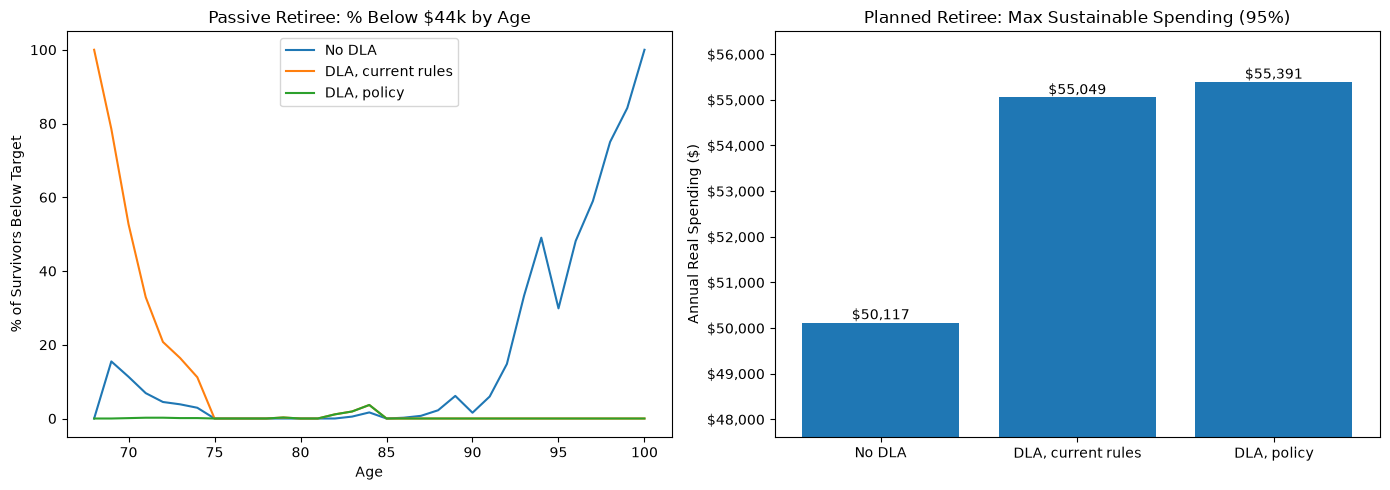

In [72]:
base = {"abp_balance": 500_000}
a = 0.10
share_minimum = 0.5   # share of retirees who draw only the minimum

cases = {"No DLA": (0, False), "DLA, current rules": (a, False), "DLA, policy": (a, True)}
rows = []
min_runs = {}
for case, (alloc, pol) in cases.items():
    r_min = monte_carlo_simulation(alloc, drawdown_rule = "minimum", policy = pol, **base)
    r_tgt = monte_carlo_simulation(alloc, policy = pol, **base)
    min_runs[case] = r_min
    rows.append({
        "Case": case,
        "Passive: yrs short /1,000": r_min['person_years_short'],
        "Passive: $ short /member": round(r_min['mean_cum_shortfall']),
        "Planned: sust. spending": round(max_sustainable_spending(alloc, policy = pol, tol = 50, **base)),
        "Age Pension /member": round(share_minimum * r_min['mean_lifetime_pension']
                                     + (1 - share_minimum) * r_tgt['mean_lifetime_pension']),
        "Blended $ short /member": round(share_minimum * r_min['mean_cum_shortfall']
                                         + (1 - share_minimum) * r_tgt['mean_cum_shortfall']),
    })

summary = pd.DataFrame(rows)
print(summary.to_string(index = False))

fig, axs = plt.subplots(1, 2, figsize = (14, 5))
for case, res in min_runs.items():
    axs[0].plot(res['ages'], res['shortfall_pct'], label = case)
axs[0].set_title('Passive Retiree: % Below $44k by Age')
axs[0].set_xlabel('Age')
axs[0].set_ylabel('% of Survivors Below Target')
axs[0].legend()

axs[1].bar(summary['Case'], summary['Planned: sust. spending'])
axs[1].set_title('Planned Retiree: Max Sustainable Spending (95%)')
axs[1].set_ylabel('Annual Real Spending ($)')
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axs[1].set_ylim(summary['Planned: sust. spending'].min() * 0.95, summary['Planned: sust. spending'].max() * 1.02)
for i, v in enumerate(summary['Planned: sust. spending']):
    axs[1].text(i, v, f'${v:,.0f}', ha = 'center', va = 'bottom')

plt.tight_layout()
plt.show()

SECTION 5: OPTIONS ASSESSMENT ($500k, 10% allocation, market pricing baseline)
                               Planned: sust. spending  Passive: $ short pre-85  Passive: $ short post-85  Mean bequest (blended)  Govt cost /member (blended)  Extra govt cost vs baseline Take-up effect Simplicity Integrity risk
Option                                                                                                                                                                                                                              
No DLA                                           50117                      174                       549                  287041                       441456                        -8429            n/a        n/a            n/a
Baseline: current rules                          51582                     1986                         0                  262153                       449885                            0            Low       High            Low
Propo

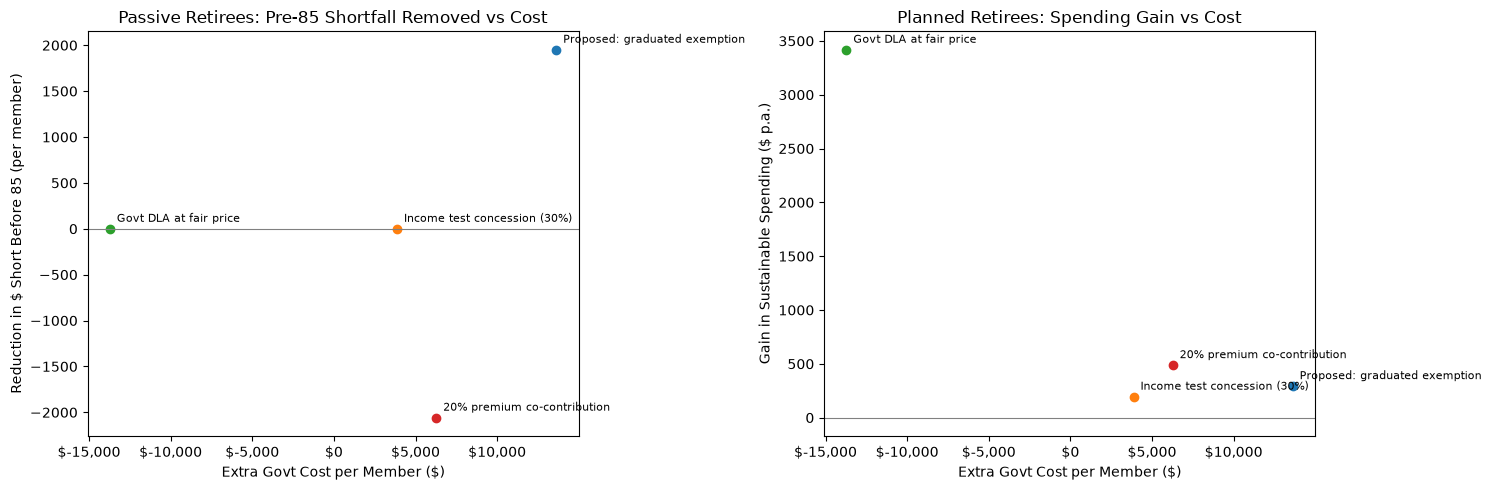

In [73]:
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 20)

share_minimum = 0.5
assess = {"abp_balance": 500_000, "price": 5.65}   # status quo: market DLA pricing
alloc_assess = 0.10

options = {
    "No DLA": {"alloc": 0},
    "Baseline: current rules": {},
    "Proposed: graduated exemption": {"asset_rule": "graduated"},
    "Income test concession (30%)": {"income_pct": 0.3},
    "Govt DLA at fair price": {"price": price_per_dollar},
    "20% premium co-contribution": {"co_contribution": 0.2},
}

def run_option(opt, **overrides):
    opt = dict(opt)
    alloc = opt.pop("alloc", alloc_assess)
    kw = {**assess, **opt, **overrides}
    r_min = monte_carlo_simulation(alloc, drawdown_rule = "minimum", **kw)
    r_tgt = monte_carlo_simulation(alloc, **kw)
    return alloc, kw, r_min, r_tgt

def blend(r_min, r_tgt, key, share = None):
    s = share_minimum if share is None else share
    return s * r_min[key] + (1 - s) * r_tgt[key]

rows = []
for name, opt in options.items():
    alloc, kw, r_min, r_tgt = run_option(opt)
    rows.append({
        "Option": name,
        "Planned: sust. spending": round(max_sustainable_spending(alloc, tol = 100, **kw)),
        "Passive: $ short pre-85": round(r_min['mean_short_pre85']),
        "Passive: $ short post-85": round(r_min['mean_short_post85']),
        "Mean bequest (blended)": round(blend(r_min, r_tgt, 'mean_bequest')),
        "Govt cost /member (blended)": round(blend(r_min, r_tgt, 'govt_cost')),
    })

results_5 = pd.DataFrame(rows).set_index("Option")
base_cost = results_5.loc["Baseline: current rules", "Govt cost /member (blended)"]
results_5["Extra govt cost vs baseline"] = results_5["Govt cost /member (blended)"] - base_cost

# Qualitative criteria: proposed ratings, for the group to review and edit
qualitative = pd.DataFrame({
    "Take-up effect": ["n/a", "Low", "Medium-High", "Low", "Medium-High", "High"],
    "Simplicity": ["n/a", "High", "Medium", "High", "Low", "Medium"],
    "Integrity risk": ["n/a", "Low", "Medium", "Low", "Low", "Medium"],
}, index = results_5.index)

assessment = results_5.join(qualitative)
print("SECTION 5: OPTIONS ASSESSMENT ($500k, 10% allocation, market pricing baseline)")
print(assessment.to_string())
assessment.to_csv("options_assessment.csv")

# Cost-effectiveness: what each $ of government cost buys
base_pre85 = results_5.loc["Baseline: current rules", "Passive: $ short pre-85"]
base_spend = results_5.loc["Baseline: current rules", "Planned: sust. spending"]
plot_df = results_5.drop(index = ["No DLA", "Baseline: current rules"])

fig, axs = plt.subplots(1, 2, figsize = (15, 5))
for name, row in plot_df.iterrows():
    axs[0].scatter(row["Extra govt cost vs baseline"], base_pre85 - row["Passive: $ short pre-85"])
    axs[0].annotate(name, (row["Extra govt cost vs baseline"], base_pre85 - row["Passive: $ short pre-85"]),
                    textcoords = "offset points", xytext = (5, 5), fontsize = 8)
    axs[1].scatter(row["Extra govt cost vs baseline"], row["Planned: sust. spending"] - base_spend)
    axs[1].annotate(name, (row["Extra govt cost vs baseline"], row["Planned: sust. spending"] - base_spend),
                    textcoords = "offset points", xytext = (5, 5), fontsize = 8)
axs[0].set_title('Passive Retirees: Pre-85 Shortfall Removed vs Cost')
axs[0].set_ylabel('Reduction in $ Short Before 85 (per member)')
axs[1].set_title('Planned Retirees: Spending Gain vs Cost')
axs[1].set_ylabel('Gain in Sustainable Spending ($ p.a.)')
for ax in axs:
    ax.set_xlabel('Extra Govt Cost per Member ($)')
    ax.axhline(0, color = 'grey', lw = 0.8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

In [74]:
rows = []
for bal in [400_000, 500_000, 600_000]:
    _, _, b_min, b_tgt = run_option(options["Baseline: current rules"], abp_balance = bal)
    for name, opt in options.items():
        if name in ("No DLA", "Baseline: current rules"):
            continue
        _, _, r_min, r_tgt = run_option(opt, abp_balance = bal)
        rows.append({
            "Balance": f"${bal/1000:.0f}k",
            "Option": name,
            "Pre-85 short removed (passive)": round(b_min['mean_short_pre85'] - r_min['mean_short_pre85']),
            "Extra govt cost": round(blend(r_min, r_tgt, 'govt_cost') - blend(b_min, b_tgt, 'govt_cost')),
        })

targeting = pd.DataFrame(rows).pivot(index = "Option", columns = "Balance")
print("SECTION 5: TARGETING ACROSS THE COHORT (vs current rules at the same balance)")
print(targeting.to_string())
targeting.to_csv("options_targeting.csv")

SECTION 5: TARGETING ACROSS THE COHORT (vs current rules at the same balance)
                              Pre-85 short removed (passive)              Extra govt cost              
Balance                                                $400k $500k  $600k           $400k  $500k  $600k
Option                                                                                                 
20% premium co-contribution                                0 -2058  -4413            7055   6269   6097
Govt DLA at fair price                                     0     0      0          -11081 -13720 -16220
Income test concession (30%)                               0     0      0            2719   3866   4689
Proposed: graduated exemption                              0  1951  13699            1956  13617  22710


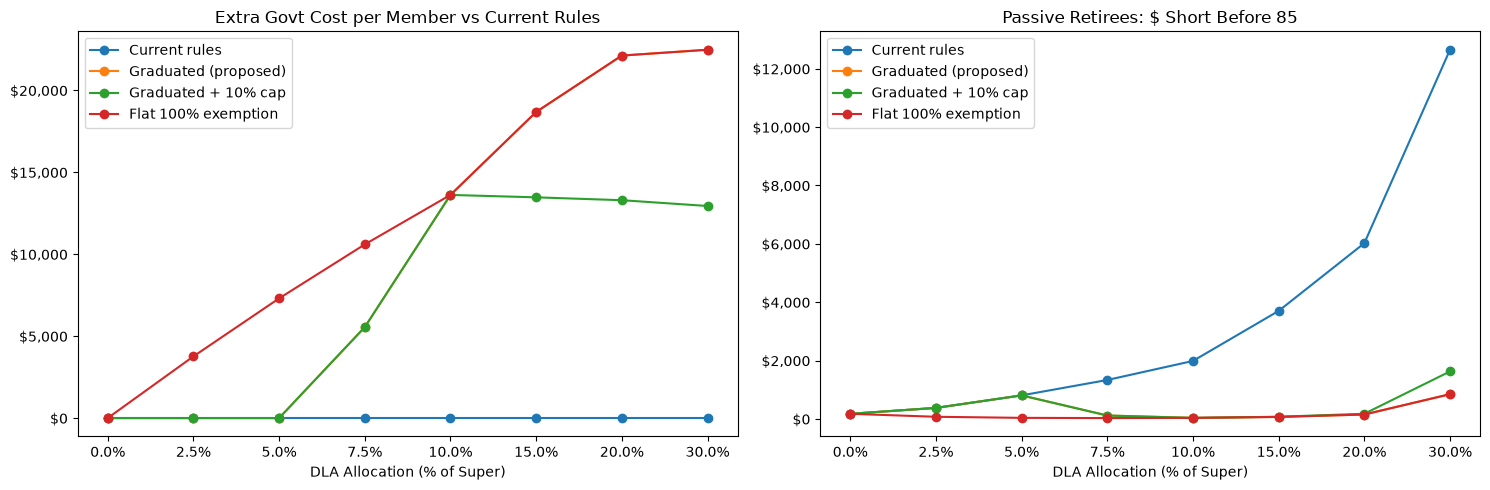

SECTION 6: MARGINAL EXTRA GOVT COST PER ALLOCATION STEP (integrity: where the incentive is steepest)
                Current rules  Graduated (proposed)  Graduated + 10% cap  Flat 100% exemption
0.0% -> 2.5%              0.0                   0.0                  0.0               3763.0
2.5% -> 5.0%              0.0                   0.0                  0.0               3540.0
5.0% -> 7.5%              0.0                5548.0               5548.0               3293.0
7.5% -> 10.0%             0.0                8069.0               8069.0               3020.0
10.0% -> 15.0%            0.0                5062.0               -147.0               5062.0
15.0% -> 20.0%            0.0                3442.0               -174.0               3442.0
20.0% -> 30.0%            0.0                 355.0               -353.0                355.0


In [75]:
sweep_allocs = [0, 0.025, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30]
variants = {"Current rules": "current", "Graduated (proposed)": "graduated",
            "Graduated + 10% cap": "graduated_capped", "Flat 100% exemption": "flat_full"}

sweep = {v: {"cost": [], "pre85": []} for v in variants}
for a in sweep_allocs:
    _, _, c_min, c_tgt = run_option({"alloc": a, "asset_rule": "current"})
    for v, rule in variants.items():
        _, _, r_min, r_tgt = run_option({"alloc": a, "asset_rule": rule})
        sweep[v]["cost"].append(blend(r_min, r_tgt, 'govt_cost') - blend(c_min, c_tgt, 'govt_cost'))
        sweep[v]["pre85"].append(r_min['mean_short_pre85'])

x = [f'{a:.1%}' for a in sweep_allocs]
fig, axs = plt.subplots(1, 2, figsize = (15, 5))
for v in variants:
    axs[0].plot(x, sweep[v]["cost"], marker = 'o', label = v)
    axs[1].plot(x, sweep[v]["pre85"], marker = 'o', label = v)
axs[0].set_title('Extra Govt Cost per Member vs Current Rules')
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axs[1].set_title('Passive Retirees: $ Short Before 85')
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
for ax in axs:
    ax.set_xlabel('DLA Allocation (% of Super)')
    ax.legend()
plt.tight_layout()
plt.show()

marginal = pd.DataFrame({v: np.diff(sweep[v]["cost"]) for v in variants},
                        index = [f'{a:.1%} -> {b:.1%}' for a, b in zip(sweep_allocs[:-1], sweep_allocs[1:])])
print("SECTION 6: MARGINAL EXTRA GOVT COST PER ALLOCATION STEP (integrity: where the incentive is steepest)")
print(marginal.round(0).to_string())

In [76]:
stress = {
    "Base ($500k, market price)": {},
    "Lower balance ($400k)": {"abp_balance": 400_000},
    "Higher balance ($600k)": {"abp_balance": 600_000},
    "Fair DLA pricing": {"price": price_per_dollar},
    "Growth returns": {"return_type": "Growth"},
    "Higher target ($55k)": {"target": 55_000},
}

rows = []
for name, ov in stress.items():
    _, _, b_min, b_tgt = run_option(options["Baseline: current rules"], **ov)
    _, _, p_min, p_tgt = run_option(options["Proposed: graduated exemption"], **ov)
    for share in ([share_minimum, 0.63] if name.startswith("Base") else [share_minimum]):
        rows.append({
            "Scenario": name + (f" ({share:.0%} passive)" if share != share_minimum else ""),
            "Pre-85 short removed (passive)": round(b_min['mean_short_pre85'] - p_min['mean_short_pre85']),
            "Total short removed (blended)": round(blend(b_min, b_tgt, 'mean_cum_shortfall', share)
                                                   - blend(p_min, p_tgt, 'mean_cum_shortfall', share)),
            "Extra govt cost (blended)": round(blend(p_min, p_tgt, 'govt_cost', share)
                                               - blend(b_min, b_tgt, 'govt_cost', share)),
        })

stress_df = pd.DataFrame(rows).set_index("Scenario")
print("SECTION 6: STRESS TESTS OF THE PROPOSED POLICY (vs current rules)")
print(stress_df.to_string())
stress_df.to_csv("policy_stress_tests.csv")

# Aggregate fiscal cost: fill in once you have a sourced figure for eligible new retirees per year
eligible_retirees_per_year = None
if eligible_retirees_per_year:
    per_member = stress_df.loc["Base ($500k, market price)", "Extra govt cost (blended)"]
    for take_up in [0.05, 0.10, 0.20]:
        print(f"Take-up {take_up:.0%}: ${per_member * eligible_retirees_per_year * take_up / 1e6:,.1f}m "
              f"lifetime cost per annual cohort")
else:
    print("Set eligible_retirees_per_year (sourced) to estimate aggregate fiscal cost.")

SECTION 6: STRESS TESTS OF THE PROPOSED POLICY (vs current rules)
                                          Pre-85 short removed (passive)  Total short removed (blended)  Extra govt cost (blended)
Scenario                                                                                                                          
Base ($500k, market price)                                          1951                            975                      13617
Base ($500k, market price) (63% passive)                            1951                           1229                      14322
Lower balance ($400k)                                                  0                              0                       1956
Higher balance ($600k)                                             13699                           6849                      22710
Fair DLA pricing                                                    1951                            975                      13588
Growth returns   